In [52]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from sklearn.model_selection import train_test_split

In [53]:
train = pd.read_csv("FNN and CNN/CIFAR10/cifar-10.csv")
test = pd.read_csv("cifar10_test_data.csv")

display(train.head())


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [54]:
x = train.drop(columns=["label"] , axis = 1).values / 255.0
y = train["label"].values

In [55]:
x_train , x_test , y_train , y_test = train_test_split(
    x , y , random_state=42 , test_size=0.2 , stratify=y
)
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]


In [56]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (40000, 3072)
Testing images: (10000, 3072)


In [57]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
model.compile(
    optimizer= keras.optimizers.SGD(learning_rate=0.01),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [59]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3082 - loss: 1.9286 - val_accuracy: 0.3400 - val_loss: 1.8503
Epoch 2/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3750 - loss: 1.7638 - val_accuracy: 0.3945 - val_loss: 1.7300
Epoch 3/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4034 - loss: 1.6925 - val_accuracy: 0.4008 - val_loss: 1.6809
Epoch 4/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4208 - loss: 1.6424 - val_accuracy: 0.4230 - val_loss: 1.6456
Epoch 5/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4370 - loss: 1.6032 - val_accuracy: 0.4367 - val_loss: 1.6059
Epoch 6/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4470 - loss: 1.5708 - val_accuracy: 0.4665 - val_loss: 1.5681
Epoch 7/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4551 - loss: 1.5459 - val_accuracy: 0.4640 - val_loss: 1.5433
Epoch 8/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4642 - loss: 1.5210 - 

In [60]:
loss, accuracy = model.evaluate(
    x_train,
    y_train,
    verbose=1
)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 514us/step - accuracy: 0.4990 - loss: 1.4419
Validation Loss: 1.4418829679489136
Validation Accuracy: 0.49904999136924744


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


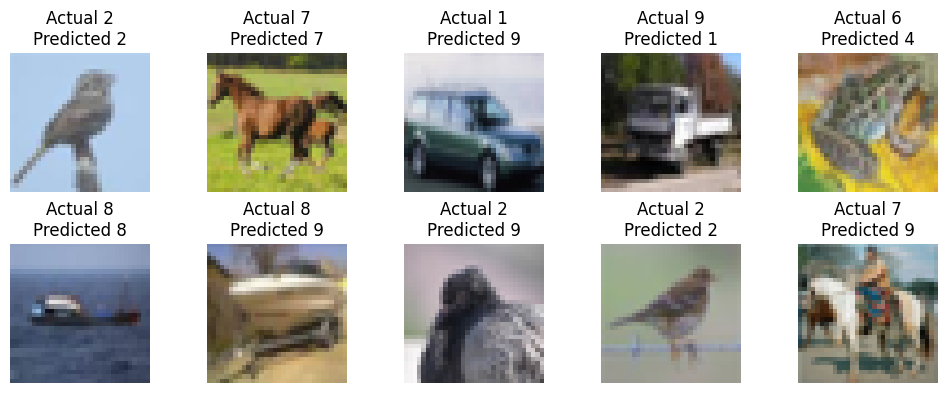

In [61]:
prediction = model.predict(x_test[:10])

predicted_digit = prediction.argmax(axis = 1)

plt.figure(figsize=(10 , 4))
for i in range(10):
    plt.subplot(2 , 5 , i+1)
    plt.imshow(x_test[i].reshape(3,32,32).transpose(1,2,0))
    plt.title(f"Actual {y_test[i]}\nPredicted {predicted_digit[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


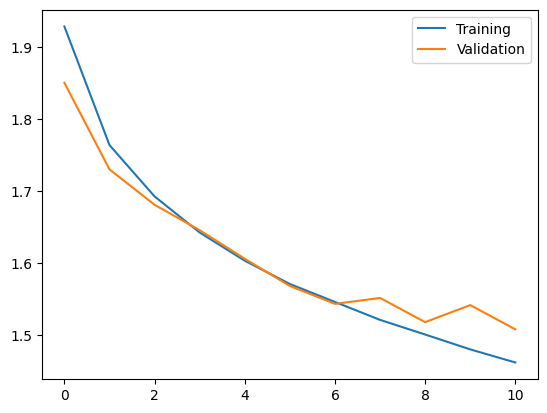

In [62]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.legend()
plt.show()

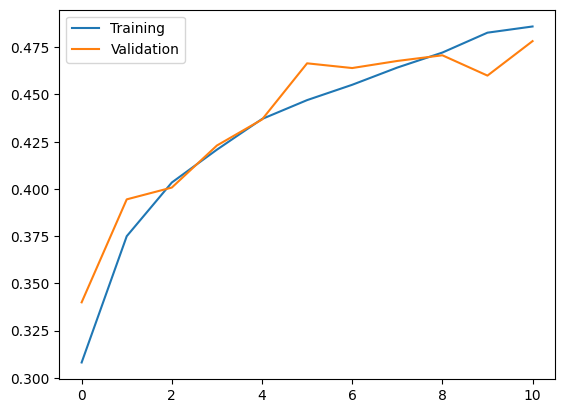

In [63]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.show()